In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

# Load tab-separated dataset




display(df.head())

,DateTime\tJunction\tVehicles\tID
0,01-11-2015 00:00\t1\t15\t20151101001
1,01-11-2015 01:00\t1\t13\t20151101011
2,01-11-2015 02:00\t1\t10\t20151101021
3,01-11-2015 03:00\t1\t7\t20151101031
4,01-11-2015 04:00\t1\t9\t20151101041


In [8]:
df = pd.read_csv(
    "../data/traffic.csv",
    sep="\t"
)

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Shape: (48120, 4)
Columns: ['DateTime', 'Junction', 'Vehicles', 'ID']


,DateTime,Junction,Vehicles,ID
0,01-11-2015 00:00,1,15,20151101001
1,01-11-2015 01:00,1,13,20151101011
2,01-11-2015 02:00,1,10,20151101021
3,01-11-2015 03:00,1,7,20151101031
4,01-11-2015 04:00,1,9,20151101041


In [12]:
df["DateTime"] = pd.to_datetime(
    df["DateTime"],
    dayfirst=True
)

print(df.dtypes)
display(df.head())

DateTime    datetime64[ns]
Junction             int64
Vehicles             int64
ID                   int64
dtype: object


,DateTime,Junction,Vehicles,ID
0,2015-11-01 00:00:00,1,15,20151101001
1,2015-11-01 01:00:00,1,13,20151101011
2,2015-11-01 02:00:00,1,10,20151101021
3,2015-11-01 03:00:00,1,7,20151101031
4,2015-11-01 04:00:00,1,9,20151101041


In [10]:
print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nStatistics:")
display(df.describe())

Dataset shape: (48120, 4)

Missing values:
DateTime    0
Junction    0
Vehicles    0
ID          0
dtype: int64

Duplicate rows:
0

Statistics:


,Junction,Vehicles,ID
count,48120.000000,48120.000000,4.812000e+04
mean,2.180549,22.791334,2.016330e+10
std,0.966955,20.750063,5.944854e+06
min,1.000000,1.000000,2.015110e+10
25%,1.000000,9.000000,2.016042e+10
50%,2.000000,15.000000,2.016093e+10
75%,3.000000,29.000000,2.017023e+10
max,4.000000,180.000000,2.017063e+10


In [13]:
df["hour"] = df["DateTime"].dt.hour

df["day_of_week"] = df["DateTime"].dt.dayofweek

df["day_name"] = df["DateTime"].dt.day_name()

print(df[[
    "DateTime",
    "Junction",
    "Vehicles",
    "hour",
    "day_of_week",
    "day_name"
]].head(10))

             DateTime  Junction  Vehicles  hour  day_of_week day_name
0 2015-11-01 00:00:00         1        15     0            6   Sunday
1 2015-11-01 01:00:00         1        13     1            6   Sunday
2 2015-11-01 02:00:00         1        10     2            6   Sunday
3 2015-11-01 03:00:00         1         7     3            6   Sunday
4 2015-11-01 04:00:00         1         9     4            6   Sunday
5 2015-11-01 05:00:00         1         6     5            6   Sunday
6 2015-11-01 06:00:00         1         9     6            6   Sunday
7 2015-11-01 07:00:00         1         8     7            6   Sunday
8 2015-11-01 08:00:00         1        11     8            6   Sunday
9 2015-11-01 09:00:00         1        12     9            6   Sunday


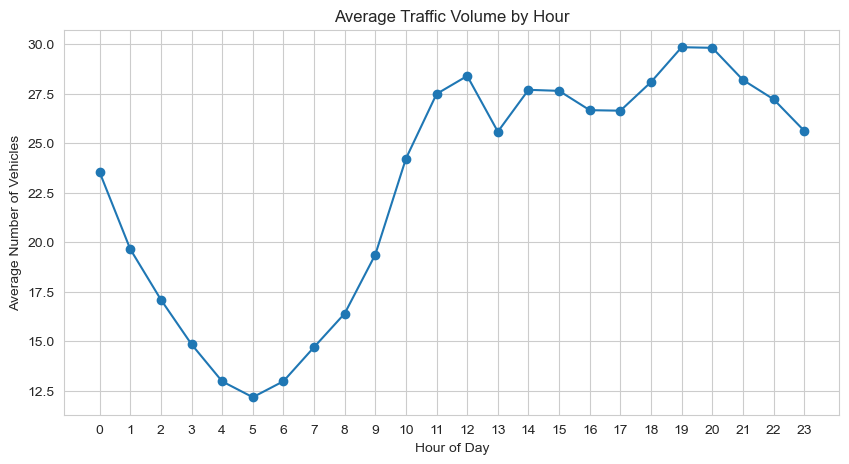

In [15]:
hourly_volume = df.groupby("hour")["Vehicles"].mean()

plt.figure(figsize=(10, 5))

plt.plot(
    hourly_volume.index,
    hourly_volume.values,
    marker="o"
)

plt.xlabel("Hour of Day")
plt.ylabel("Average Number of Vehicles")
plt.title("Average Traffic Volume by Hour")

plt.xticks(range(24))

plt.show()

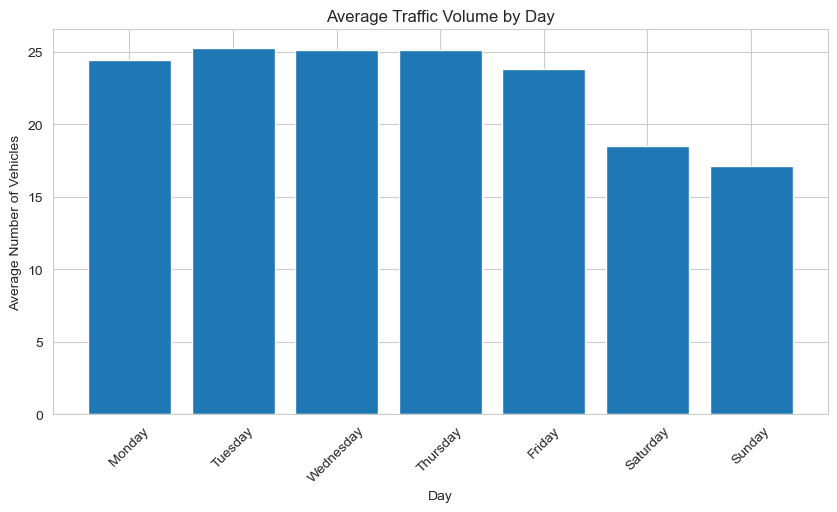

In [16]:
daily_volume = df.groupby("day_name")["Vehicles"].mean()

day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

daily_volume = daily_volume.reindex(day_order)

plt.figure(figsize=(10, 5))

plt.bar(
    daily_volume.index,
    daily_volume.values
)

plt.xlabel("Day")
plt.ylabel("Average Number of Vehicles")
plt.title("Average Traffic Volume by Day")

plt.xticks(rotation=45)

plt.show()

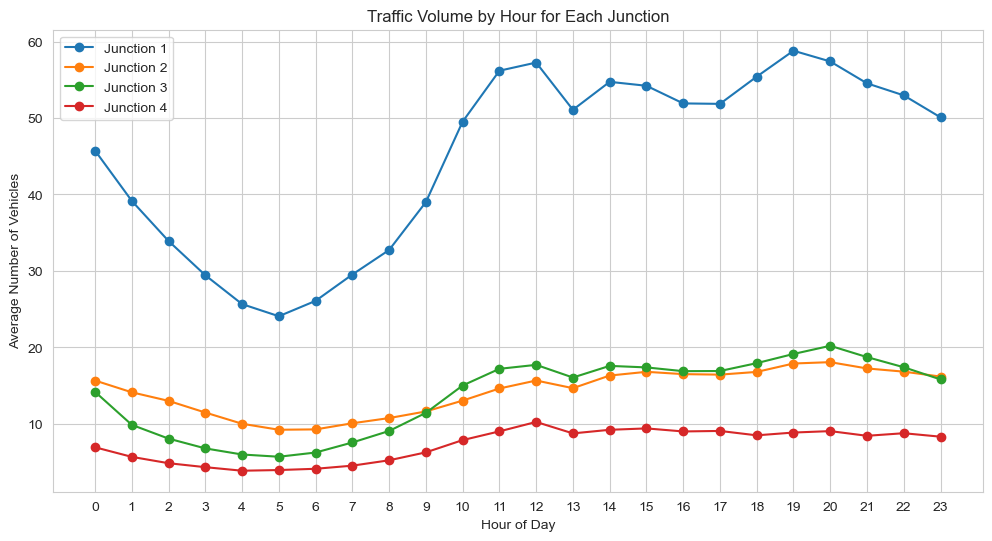

In [17]:
junction_hour = df.pivot_table(
    values="Vehicles",
    index="hour",
    columns="Junction",
    aggfunc="mean"
)

plt.figure(figsize=(12, 6))

for junction in junction_hour.columns:
    plt.plot(
        junction_hour.index,
        junction_hour[junction],
        marker="o",
        label=f"Junction {junction}"
    )

plt.xlabel("Hour of Day")
plt.ylabel("Average Number of Vehicles")
plt.title("Traffic Volume by Hour for Each Junction")

plt.xticks(range(24))
plt.legend()

plt.show()

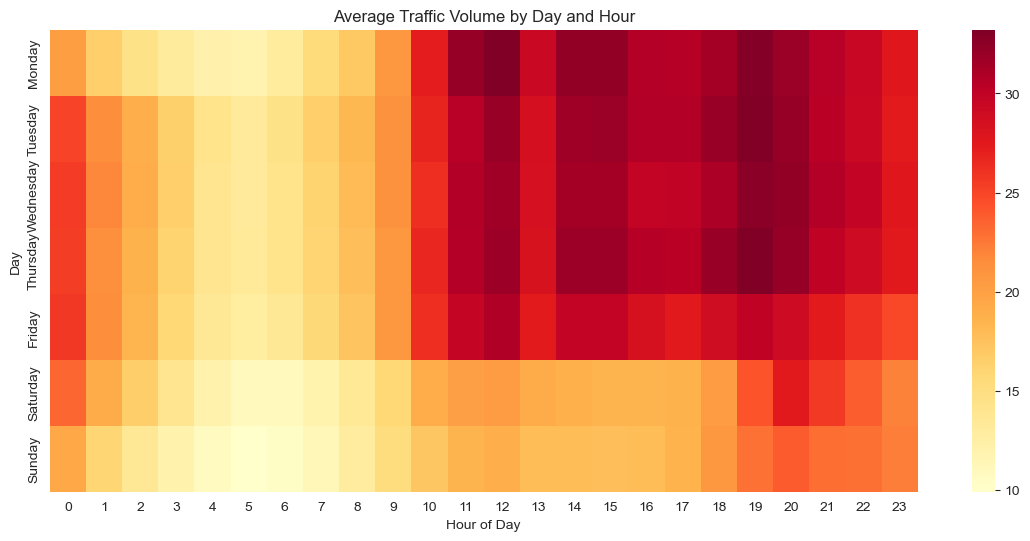

In [18]:
heatmap_data = df.pivot_table(
    values="Vehicles",
    index="day_name",
    columns="hour",
    aggfunc="mean"
)

heatmap_data = heatmap_data.reindex(day_order)

plt.figure(figsize=(14, 6))

sns.heatmap(
    heatmap_data,
    annot=False,
    cmap="YlOrRd"
)

plt.title("Average Traffic Volume by Day and Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Day")

plt.show()

In [19]:
df.to_csv(
    "../data/processed_traffic.csv",
    index=False
)

print("Processed dataset saved successfully!")

Processed dataset saved successfully!
